
# Evaluare 01: Învățarea supervizată
Acest test are scopul de a evalua cunoștințele tale despre importul datelor, vizualizarea acestora și utilizarea modelelor de machine learning.
Te rugăm să completezi cerințele direct în celulele dedicate fiecărei secțiuni.


## 1. Importul datelor
1. Importă biblioteca `pandas` și încarcă fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
2. Verifică dimensiunile și tipurile de date.
3. Afișează primele 5 rânduri din DataFrame și verifică prezența valorilor lipsă.


In [1]:
import os
import pandas as pd

fisier = 'Human_Activity_Recognition_Using_Smartphones_Data.csv'

# CSV-ul il fac din fisierele originale din arhiva (folderul "UCI HAR Dataset")
if not os.path.exists(fisier):
    folder = 'UCI HAR Dataset'
    nume_coloane = pd.read_csv(os.path.join(folder, 'features.txt'), sep=r'\s+', header=None)[1].tolist()
    activitati = pd.read_csv(os.path.join(folder, 'activity_labels.txt'), sep=r'\s+', header=None, index_col=0)[1]
    parti = []
    for parte in ['train', 'test']:
        X_parte = pd.read_csv(os.path.join(folder, parte, f'X_{parte}.txt'), sep=r'\s+', header=None)
        y_parte = pd.read_csv(os.path.join(folder, parte, f'y_{parte}.txt'), header=None)[0]
        X_parte.columns = nume_coloane
        activitate = pd.Series(y_parte.map(activitati).values, name='Activity')
        parti.append(pd.concat([X_parte, activitate], axis=1))
    pd.concat(parti, ignore_index=True).to_csv(fisier, index=False)

df = pd.read_csv(fisier)

print("Dimensiuni:", df.shape)
print("\nTipuri de date:")
print(df.dtypes.value_counts())
print("\nValori lipsa in total:", df.isnull().sum().sum())
df.head()

Dimensiuni: (10299, 562)

Tipuri de date:
float64    561
str          1
Name: count, dtype: int64

Valori lipsa in total: 0


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING



## 2. Vizualizare date cu Matplotlib și Seaborn
1. Creează un grafic scatter care să afișeze relația dintre două coloane numeric.
2. Utilizează Seaborn pentru a crea o hartă de căldură (heatmap) a corelațiilor dintre coloane.


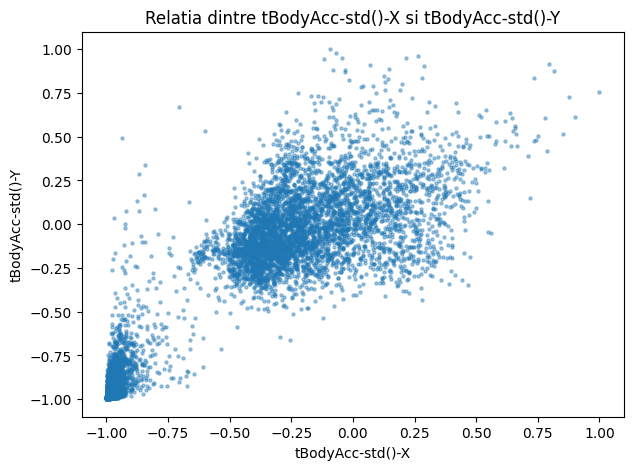

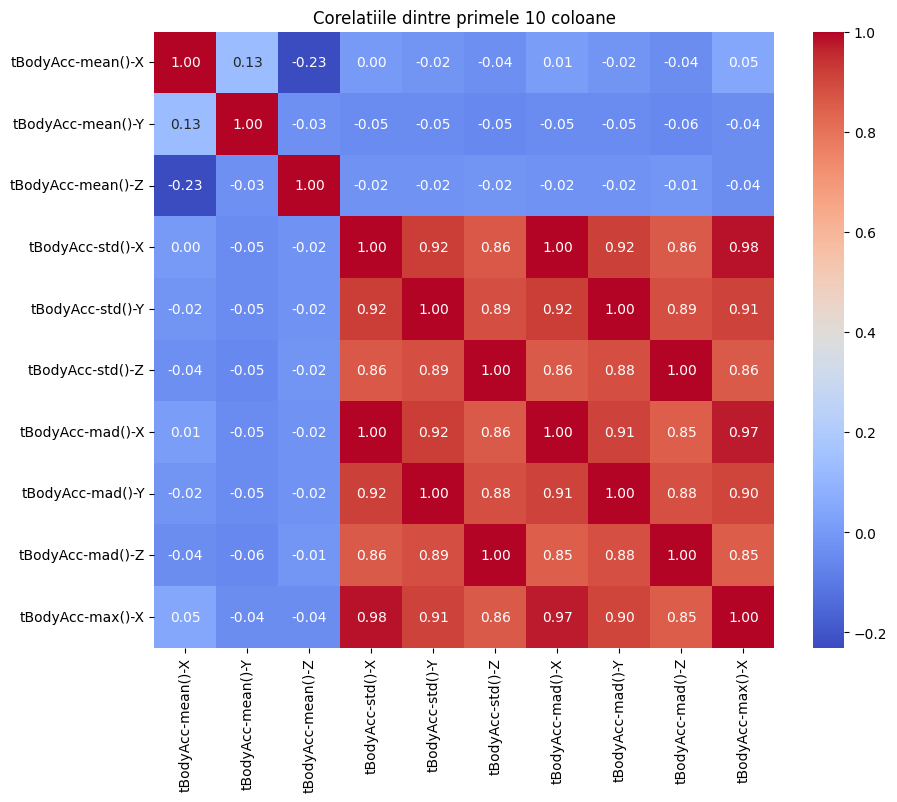

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
plt.scatter(df['tBodyAcc-std()-X'], df['tBodyAcc-std()-Y'], s=5, alpha=0.4)
plt.xlabel('tBodyAcc-std()-X')
plt.ylabel('tBodyAcc-std()-Y')
plt.title('Relatia dintre tBodyAcc-std()-X si tBodyAcc-std()-Y')
plt.show()

# setul are 561 de coloane, asa ca la heatmap iau doar primele 10 ca sa se vada ceva
coloane = df.columns[:10]
plt.figure(figsize=(10, 8))
sns.heatmap(df[coloane].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Corelatiile dintre primele 10 coloane')
plt.show()

## 3. Metrici ale erorii
1. Împarte setul de date în seturi de antrenare și testare (80%-20%).
2. Construiește un model de regresie liniară pe datele numerice.
3. Evaluează performanța modelului utilizând **MAE**, **MSE**, și **RMSE**.

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# prezic tBodyAcc-std()-X (cat de intensa e miscarea, masurata de accelerometru)
# doar din coloanele giroscopului, adica din alt senzor
X_reg = df.filter(like='Gyro')
y_reg = df['tBodyAcc-std()-X']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

model_lr = LinearRegression()
model_lr.fit(X_train_r, y_train_r)
pred_r = model_lr.predict(X_test_r)

mae = mean_absolute_error(y_test_r, pred_r)
mse = mean_squared_error(y_test_r, pred_r)
rmse = np.sqrt(mse)

print("MAE: ", round(mae, 4))
print("MSE: ", round(mse, 6))
print("RMSE:", round(rmse, 4))

MAE:  0.0686
MSE:  0.011457
RMSE: 0.107



## 4. Validare încrucișată (Cross Validation)
1. Importă biblioteca `scikit-learn`.
2. Împarte setul de date în seturi de antrenare și testare (80%-20%).
3. Utilizează `cross_val_score` pentru a evalua performanța unui model KNN pe setul de date.


In [4]:
import sklearn
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

print("scikit-learn", sklearn.__version__)

X = df.drop(columns='Activity')
y = df['Activity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# datele sunt deja normalizate in [-1, 1], deci nu mai fac scalare
knn = KNeighborsClassifier(n_neighbors=5)
scoruri = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')

print("Acuratete pe fiecare fold:", scoruri.round(4))
print("Acuratete medie:", round(scoruri.mean(), 4), "+/-", round(scoruri.std(), 4))

scikit-learn 1.8.0


Acuratete pe fiecare fold: [0.9684 0.9636 0.966  0.966  0.9654]
Acuratete medie: 0.9659 +/- 0.0016



## 5. Modele de Machine Learning
1. **Regresia liniară**: Antrenează un model de regresie liniară și evaluează performanța acestuia pe setul de testare.
2. **Regresia logistică**: Construiește un model logistic pentru o problemă de clasificare binară.
3. **SVM**: Antrenează un model SVM și testează-l pe setul de date.


In [5]:
from sklearn.metrics import r2_score

model_lin = LinearRegression()
model_lin.fit(X_train_r, y_train_r)
pred_lin = model_lin.predict(X_test_r)

print("Regresie liniara pe setul de test:")
print("R2:  ", round(r2_score(y_test_r, pred_lin), 4))
print("MAE: ", round(mean_absolute_error(y_test_r, pred_lin), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_r, pred_lin)), 4))

Regresie liniara pe setul de test:
R2:   0.9404
MAE:  0.0686
RMSE: 0.107


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# clasificare binara: 1 = in miscare (mers, urcat, coborat scari), 0 = static (stat jos, in picioare, intins)
in_miscare = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS']
y_bin_train = y_train.isin(in_miscare).astype(int)
y_bin_test = y_test.isin(in_miscare).astype(int)

log_bin = LogisticRegression(max_iter=1000)
log_bin.fit(X_train, y_bin_train)

print("Acuratete regresie logistica (in miscare / static):", round(accuracy_score(y_bin_test, log_bin.predict(X_test)), 4))

Acuratete regresie logistica (in miscare / static): 0.9995


In [7]:
from sklearn.svm import SVC

svm = SVC()
svm.fit(X_train, y_train)

print("Acuratete SVM pe test:", round(accuracy_score(y_test, svm.predict(X_test)), 4))

Acuratete SVM pe test: 0.9757


## 6. Matricea de confuzie
1. Construiește un model de clasificare logistică.
2. Creează matricea de confuzie și afișează-o grafic utilizând Seaborn.

Acuratete regresie logistica: 0.9864


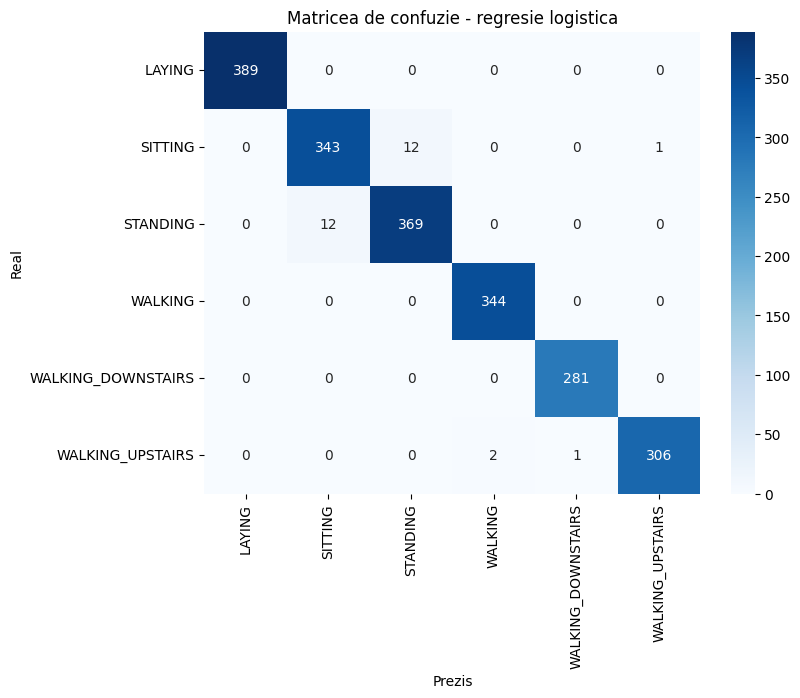

In [8]:
from sklearn.metrics import confusion_matrix

log_multi = LogisticRegression(max_iter=1000)
log_multi.fit(X_train, y_train)
pred_log = log_multi.predict(X_test)

print("Acuratete regresie logistica:", round(accuracy_score(y_test, pred_log), 4))

etichete = sorted(y.unique())
cm = confusion_matrix(y_test, pred_log, labels=etichete)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=etichete, yticklabels=etichete)
plt.xlabel('Prezis')
plt.ylabel('Real')
plt.title('Matricea de confuzie - regresie logistica')
plt.show()


## 7. Gradient Descent
1. Implementați manual algoritmul Gradient Descent pentru a optimiza o funcție cost definită.
2. Utilizați o funcție simplă $$J(\theta) = (\theta x - y)^2 $$ pe un subset al datelor.

In [9]:
# subset: primele 200 de randuri, x si y sunt doua coloane legate intre ele
subset = df.iloc[:200]
x = subset['tBodyAcc-std()-X'].to_numpy()
y_gd = subset['tBodyAcc-mad()-X'].to_numpy()

# J(theta) = media lui (theta * x - y)^2, iar derivata e media lui 2 * x * (theta * x - y)
theta = 0.0
rata_invatare = 0.1

for pas in range(201):
    eroare = theta * x - y_gd
    cost = np.mean(eroare ** 2)
    gradient = np.mean(2 * x * eroare)
    if pas % 25 == 0:
        print(f"pas {pas:3d}: theta = {theta:.4f}, J = {cost:.6f}")
    theta = theta - rata_invatare * gradient

theta_exact = np.sum(x * y_gd) / np.sum(x ** 2)
print("\ntheta gasit cu gradient descent:", round(theta, 4))
print("theta exact (din formula):     ", round(theta_exact, 4))

pas   0: theta = 0.0000, J = 0.528992
pas  25: theta = 0.9454, J = 0.003880
pas  50: theta = 1.0080, J = 0.001577
pas  75: theta = 1.0122, J = 0.001567
pas 100: theta = 1.0124, J = 0.001567
pas 125: theta = 1.0125, J = 0.001567
pas 150: theta = 1.0125, J = 0.001567
pas 175: theta = 1.0125, J = 0.001567
pas 200: theta = 1.0125, J = 0.001567

theta gasit cu gradient descent: 1.0125
theta exact (din formula):      1.0125


## 8. Modele de Machine Learning (part 2 - poate fi omis)
1. **Random Forest**: Utilizează Random Forest pentru a antrena un model și evaluează importanța caracteristicilor.
2. **Boosting și Bagging**: Compară performanța dintre un model AdaBoost și un model Bagging.


Am omis punctul 8, e optional.


## 9. Stacking
1. Construiește un model de tip Stacking utilizând Random Forest, SVM și Logistic Regression ca modele de bază.
2. Utilizează un model Logistic Regression ca meta-model.
3. Afișează acuratețea finală pe setul de testare.

In [10]:
from sklearn.ensemble import RandomForestClassifier, StackingClassifier

modele_baza = [
    ('rf', RandomForestClassifier(random_state=42)),
    ('svm', SVC(random_state=42)),
    ('lr', LogisticRegression(max_iter=1000)),
]

stacking = StackingClassifier(estimators=modele_baza,
                              final_estimator=LogisticRegression(max_iter=1000),
                              n_jobs=-1)
stacking.fit(X_train, y_train)

print("Acuratete finala Stacking pe test:", round(accuracy_score(y_test, stacking.predict(X_test)), 4))

Acuratete finala Stacking pe test: 0.9893



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
